# Task 7 – Titanic Survival Prediction using Logistic Regression

**Goal:** classify whether a passenger survived the Titanic using **logistic regression written from scratch** (class-based, trained with batch gradient descent). Only **NumPy and pandas** are used – plots are drawn with pandas' built-in plotting.


In [1]:
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 40)
np.random.seed(42)

## 1. Load the data

In [2]:
df = pd.read_csv('titanic.csv')
print('Shape:', df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
print('Missing values :', df.isna().sum().sum())
print('Duplicate rows :', df.duplicated().sum())
print()
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().T

Missing values : 866
Duplicate rows : 0

Age         177
Cabin       687
Embarked      2
dtype: int64


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


## 2. Data cleaning and train / test split

### Cleaning

In [ ]:
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()
print(df['Title'].value_counts().to_dict())

df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')
df['Title'].value_counts()

{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}


Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

In [ ]:
print(f"Cabin missing: {df['Cabin'].isna().mean():.1%}")
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
print('Remaining columns:', df.columns.tolist())

Cabin missing: 77.1%
Remaining columns: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title']


### Train / test split 

In [ ]:
def stratified_split(y, held_out_size=0.2, seed=67):
    rng = np.random.default_rng(seed)
    held = []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        held.extend(idx[:int(round(len(idx) * held_out_size))])
    held = np.array(held)
    rest = np.setdiff1d(np.arange(len(y)), held)
    rng.shuffle(rest); rng.shuffle(held)
    return rest, held

train_idx, test_idx = stratified_split(df['Survived'].values, 0.2, seed=67)
train_df = df.iloc[train_idx].reset_index(drop=True)
test_df  = df.iloc[test_idx].reset_index(drop=True)

print('Train:', train_df.shape, ' Test:', test_df.shape)
print(f"Survival rate  train: {train_df['Survived'].mean():.3f} | test: {test_df['Survived'].mean():.3f}")

Train: (713, 9)  Test: (178, 9)
Survival rate  train: 0.384 | test: 0.382


## 3. Exploratory visualisation

### Distribution of the target (Survived)

Overall survival rate: 0.384


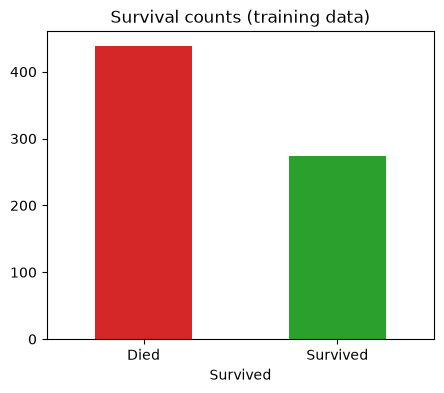

In [8]:
train_df['Survived'].value_counts().sort_index().rename({0: 'Died', 1: 'Survived'}).plot.bar(
    figsize=(5, 4), title='Survival counts (training data)', rot=0, color=['tab:red', 'tab:green'])
print('Overall survival rate:', round(train_df['Survived'].mean(), 3))

### Correlation of numeric features with survival

<Axes: title={'center': 'Correlation with Survived'}>

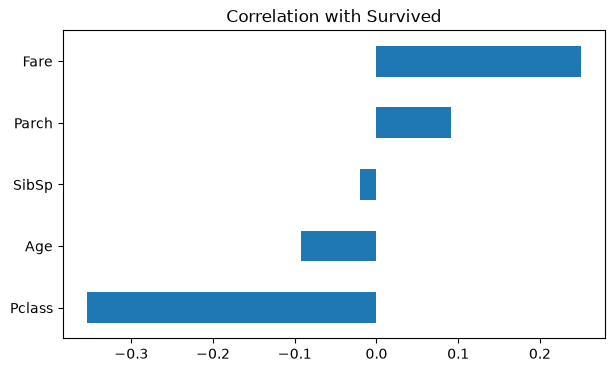

In [9]:
num_cols = train_df.select_dtypes(include=np.number).columns
corr = train_df[num_cols].corr()
corr['Survived'].drop('Survived').sort_values().plot.barh(figsize=(7, 4), title='Correlation with Survived')

In [10]:
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1).format('{:.2f}')

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.00,-0.35,-0.09,-0.02,0.09,0.25
Pclass,-0.35,1.00,-0.37,0.08,0.05,-0.55
Age,-0.09,-0.37,1.00,-0.31,-0.21,0.10
SibSp,-0.02,0.08,-0.31,1.00,0.42,0.16
Parch,0.09,0.05,-0.21,0.42,1.00,0.21
Fare,0.25,-0.55,0.10,0.16,0.21,1.00


### Key relationships

<Axes: title={'center': 'Age distribution by outcome'}, ylabel='Frequency'>

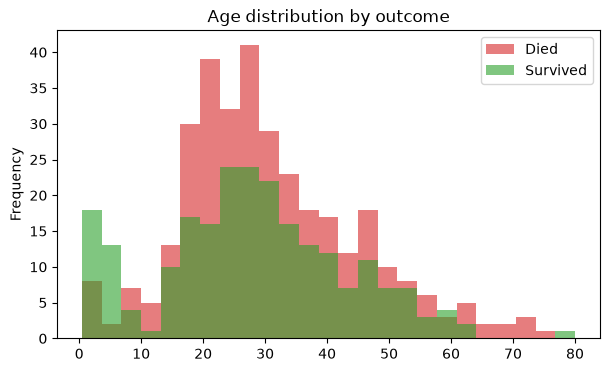

In [11]:
pd.DataFrame({'Died': train_df.loc[train_df['Survived'] == 0, 'Age'],
              'Survived': train_df.loc[train_df['Survived'] == 1, 'Age']}).plot.hist(
    bins=25, alpha=0.6, figsize=(7, 4), title='Age distribution by outcome', color=['tab:red', 'tab:green'])

<Axes: title={'center': 'log(1 + Fare) distribution by outcome'}, ylabel='Frequency'>

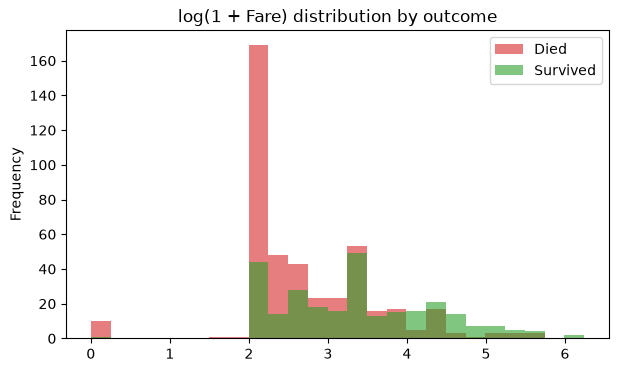

In [12]:
pd.DataFrame({'Died': np.log1p(train_df.loc[train_df['Survived'] == 0, 'Fare']),
              'Survived': np.log1p(train_df.loc[train_df['Survived'] == 1, 'Fare'])}).plot.hist(
    bins=25, alpha=0.6, figsize=(7, 4), title='log(1 + Fare) distribution by outcome', color=['tab:red', 'tab:green'])

<Axes: title={'center': 'Survival rate by family size'}, xlabel='FamilySize', ylabel='Survival rate'>

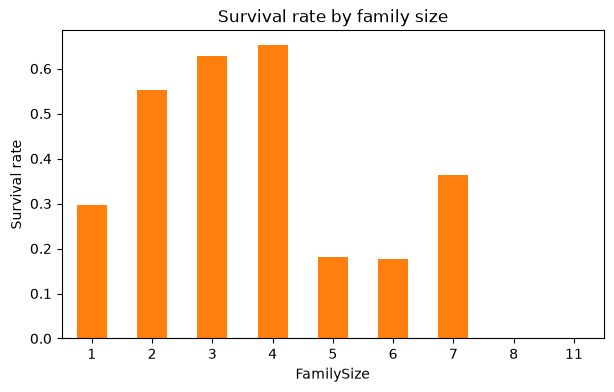

In [13]:
(train_df.assign(FamilySize=train_df['SibSp'] + train_df['Parch'] + 1)
         .groupby('FamilySize')['Survived'].mean()
         .plot.bar(figsize=(7, 4), title='Survival rate by family size', rot=0, color='tab:orange', ylabel='Survival rate'))

### Categorical features vs survival

<Axes: title={'center': 'Survival rate by sex'}, xlabel='Sex', ylabel='Survival rate'>

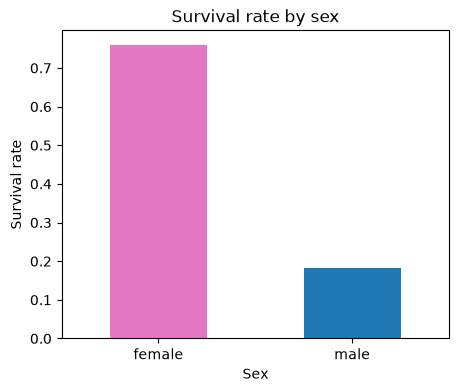

In [14]:
train_df.groupby('Sex')['Survived'].mean().plot.bar(figsize=(5, 4), title='Survival rate by sex', rot=0, color=['tab:pink', 'tab:blue'], ylabel='Survival rate')

<Axes: title={'center': 'Survival rate by passenger class'}, xlabel='Pclass', ylabel='Survival rate'>

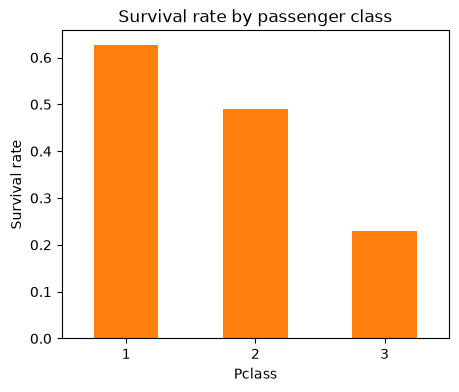

In [15]:
train_df.groupby('Pclass')['Survived'].mean().plot.bar(figsize=(5, 4), title='Survival rate by passenger class', rot=0, color='tab:orange', ylabel='Survival rate')

In [17]:
train_df.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.566176,136
Q,0.396552,58
S,0.332689,517


<Axes: title={'center': 'Survival rate by title'}, ylabel='Title'>

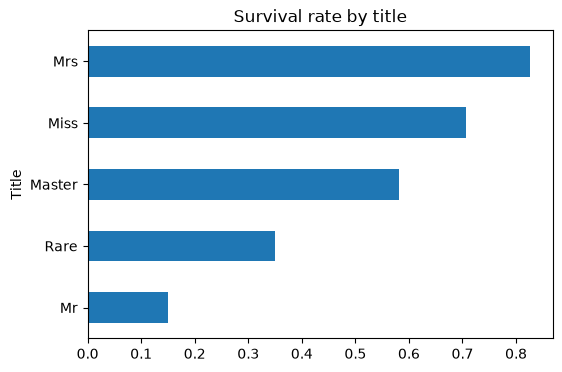

In [18]:
train_df.groupby('Title')['Survived'].mean().sort_values().plot.barh(figsize=(6, 4), title='Survival rate by title')

<Axes: title={'center': 'Age'}, xlabel='Survived'>

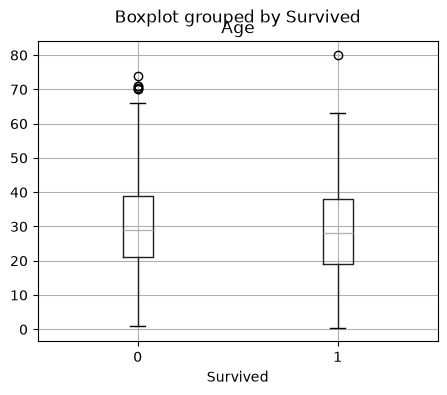

In [19]:
train_df.boxplot(column='Age', by='Survived', figsize=(5, 4))

## 4. Preprocessing

### Missing values and outliers

In [20]:
print('Missing values in the training data:')
print(train_df.isna().sum()[train_df.isna().sum() > 0])
print('\nMedian age by title (training data):')
print(train_df.groupby('Title')['Age'].median())

Missing values in the training data:
Age         147
Embarked      2
dtype: int64

Median age by title (training data):
Title
Master     3.0
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      49.0
Name: Age, dtype: float64


Age        9
Fare      92
SibSp     35
Parch    166
dtype: int64

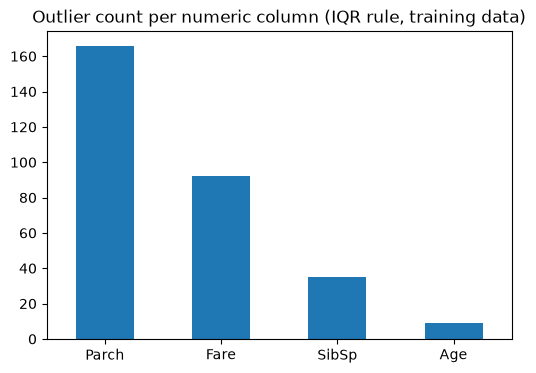

In [21]:
num_feats = ['Age', 'Fare', 'SibSp', 'Parch']
q1, q3 = train_df[num_feats].quantile(0.25), train_df[num_feats].quantile(0.75)
iqr = q3 - q1
outliers = ((train_df[num_feats] < q1 - 1.5 * iqr) | (train_df[num_feats] > q3 + 1.5 * iqr)).sum()
outliers.sort_values(ascending=False).plot.bar(figsize=(6, 4), title='Outlier count per numeric column (IQR rule, training data)', rot=0)
outliers

### Preprocessing as *fit* and *transform*

In [ ]:
REFERENCE_COLS = ['Pclass_1', 'Embarked_C', 'Title_Master']     

def encode(d, p):
    d = d.copy()
    d['Age'] = d['Age'].fillna(d['Title'].map(p['age_by_title'])).fillna(p['age_overall'])
    d['Embarked'] = d['Embarked'].fillna(p['embarked_mode'])
    d['Fare'] = d['Fare'].fillna(p['fare_median'])
    d['FamilySize'] = d['SibSp'] + d['Parch'] + 1
    d['IsAlone'] = (d['FamilySize'] == 1).astype(int)
    d['Fare'] = np.log1p(d['Fare'])
    d['Sex'] = (d['Sex'] == 'female').astype(int)        
    d = d.drop(columns=['SibSp', 'Parch'])
    return pd.get_dummies(d, columns=['Pclass', 'Embarked', 'Title'], dtype=float)

def fit_preprocessing(d):
    p = {'age_by_title': d.groupby('Title')['Age'].median(),
         'age_overall':  d['Age'].median(),
         'embarked_mode': d['Embarked'].mode()[0],
         'fare_median':  d['Fare'].median()}
    enc = encode(d, p).drop(columns=['Survived'] + REFERENCE_COLS)
    p['columns'] = enc.columns.tolist()
    p['mu'] = enc.values.mean(axis=0)
    sigma = enc.values.std(axis=0)
    sigma[sigma == 0] = 1.0
    p['sigma'] = sigma
    return p

def transform(d, p):
    enc = encode(d, p).reindex(columns=['Survived'] + p['columns'], fill_value=0.0)
    X = (enc[p['columns']].values.astype(float) - p['mu']) / p['sigma']
    return X, enc['Survived'].values.astype(float)

###  Development split: fitting part and validation part

In [ ]:
fit_idx, val_idx = stratified_split(train_df['Survived'].values, 0.2, seed=1)    
fit_df, val_df = train_df.iloc[fit_idx], train_df.iloc[val_idx]
assert len(fit_df) > len(val_df)                                              

prep_dev = fit_preprocessing(fit_df)
X_fit, y_fit = transform(fit_df, prep_dev)
X_val, y_val = transform(val_df, prep_dev)
feature_names = prep_dev['columns']
assert not np.isnan(X_fit).any() and not np.isnan(X_val).any()

print('Fitting part:', X_fit.shape, ' Validation part:', X_val.shape)
print('Features:', feature_names)
print('Learned median age by title:', prep_dev['age_by_title'].round(1).to_dict())

Fitting part: (570, 13)  Validation part: (143, 13)
Features: ['Sex', 'Age', 'Fare', 'FamilySize', 'IsAlone', 'Pclass_2', 'Pclass_3', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']
Learned median age by title: {'Master': 3.0, 'Miss': 20.0, 'Mr': 30.0, 'Mrs': 35.0, 'Rare': 50.0}


## 5. Logistic regression

Model: $\hat{y} = \sigma(Xw + b)$, where $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ gives the probability of survival.

Training objective (binary cross-entropy + L2 penalty on the weights, bias not penalised):
$$J(w, b) = -\frac{1}{m}\sum \Big[y\log\hat y + (1-y)\log(1-\hat y)\Big] + \frac{\lambda}{2m}\sum_j w_j^2$$

Gradients:
$$\frac{\partial J}{\partial w} = \frac{1}{m}X^T(\hat y - y) + \frac{\lambda}{m}w \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum(\hat y - y)$$

Update: $w \leftarrow w - \alpha\,\partial J/\partial w$, $\;b \leftarrow b - \alpha\,\partial J/\partial b$, repeated for each epoch. A passenger is predicted as *survived* when $\hat y \ge 0.5$.


In [ ]:
class LogisticRegressionScratch:
    def __init__(self, lr=0.1, epochs=1000, lam=0.0, threshold=0.5):
        self.lr, self.epochs, self.lam, self.threshold = lr, epochs, lam, threshold
        self.w, self.b = None, 0.0
        self.train_loss, self.val_loss = [], []

    @staticmethod
    def sigmoid(z):
            return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(int)

    def cost(self, X, y):
        p = np.clip(self.predict_proba(X), 1e-15, 1 - 1e-15)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def fit(self, X, y, X_val=None, y_val=None):
        m, n = X.shape
        self.w, self.b = np.zeros(n), 0.0
        self.train_loss, self.val_loss = [], []
        for _ in range(self.epochs):
            err = self.predict_proba(X) - y
            self.w -= self.lr * (X.T @ err / m + (self.lam / m) * self.w)  
            self.b -= self.lr * err.mean()
            self.train_loss.append(self.cost(X, y))
            if X_val is not None:
                self.val_loss.append(self.cost(X_val, y_val))
        return self

### Pick hyper-parameters (learning rate, λ) 

<Axes: title={'center': 'Effect of learning rate on training loss'}, xlabel='Epoch', ylabel='Loss (log scale)'>

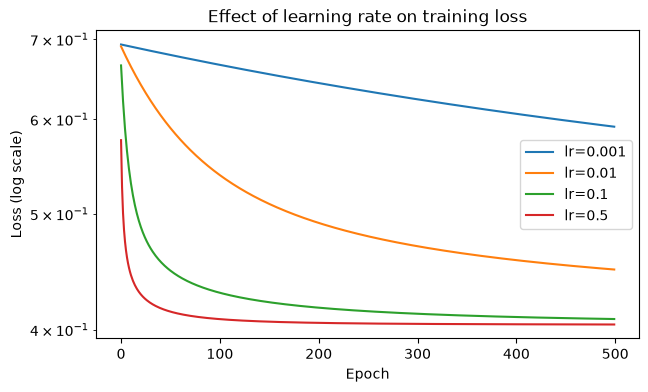

In [25]:
lr_hist = {}
for lr in [0.001, 0.01, 0.1, 0.5]:
    lr_hist[f'lr={lr}'] = LogisticRegressionScratch(lr=lr, epochs=500).fit(X_fit, y_fit).train_loss
pd.DataFrame(lr_hist).plot(figsize=(7, 4), title='Effect of learning rate on training loss', logy=True,
                           xlabel='Epoch', ylabel='Loss (log scale)')

Best λ = 3.0


,Validation loss,Validation accuracy
lambda,,
0.0,0.3668,0.8392
0.1,0.3668,0.8392
1.0,0.3661,0.8392
3.0,0.3654,0.8392
10.0,0.3668,0.8392
30.0,0.3776,0.8392
100.0,0.4109,0.8252


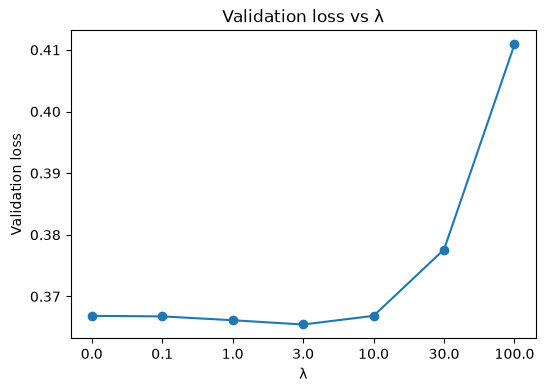

In [ ]:
rows = {}
for lam in [0, 0.1, 1, 3, 10, 30, 100]:
    mdl = LogisticRegressionScratch(lr=0.1, epochs=1000, lam=lam).fit(X_fit, y_fit)       
    rows[lam] = {'Validation loss': mdl.cost(X_val, y_val),                                
                 'Validation accuracy': np.mean(mdl.predict(X_val) == y_val)}
lam_table = pd.DataFrame(rows).T
lam_table.index.name = 'lambda'
lam_table['Validation loss'].rename(index=str).plot(marker='o', figsize=(6, 4), title='Validation loss vs λ',
                                                    xlabel='λ', ylabel='Validation loss')
best_lam = lam_table['Validation loss'].idxmin()
print('Best λ =', best_lam)
lam_table.round(4)

### Development run (training vs validation loss)

In [27]:
LR, EPOCHS, LAM = 0.1, 1000, best_lam
dev_model = LogisticRegressionScratch(lr=LR, epochs=EPOCHS, lam=LAM).fit(X_fit, y_fit, X_val, y_val)
print(f'Final fitting loss: {dev_model.train_loss[-1]:.5f} | final validation loss: {dev_model.val_loss[-1]:.5f}')

Final fitting loss: 0.40708 | final validation loss: 0.36544


### Final training on the full training set

In [28]:
prep_final = fit_preprocessing(train_df)
X_train, y_train = transform(train_df, prep_final)

model = LogisticRegressionScratch(lr=LR, epochs=EPOCHS, lam=LAM).fit(X_train, y_train)
print('Final model trained on', X_train.shape[0], 'passengers with λ =', LAM)
print(f'Final training loss: {model.train_loss[-1]:.5f}')

Final model trained on 713 passengers with λ = 3.0
Final training loss: 0.39546


## 6. Loss graph (loss vs epoch)

### Training vs validation loss (development run)

<Axes: title={'center': 'Loss vs Epoch (gradient descent)'}, xlabel='Epoch', ylabel='Binary cross-entropy loss'>

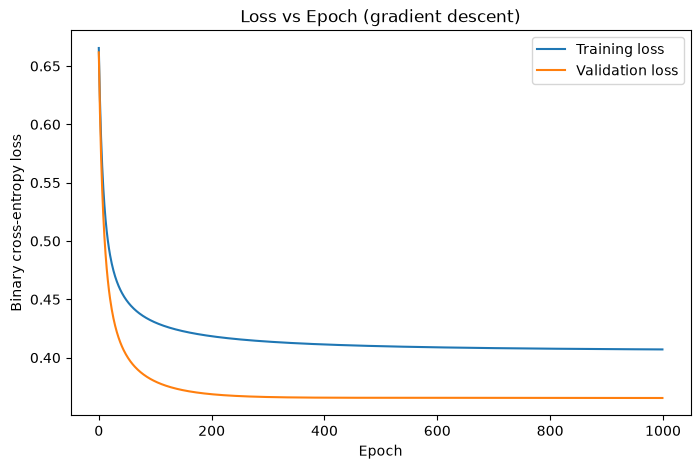

In [ ]:
loss_df = pd.DataFrame({'Training loss': dev_model.train_loss, 'Validation loss': dev_model.val_loss})
loss_df.index.name = 'Epoch'\


loss_df.plot(figsize=(8, 5), title='Loss vs Epoch (gradient descent)', xlabel='Epoch', ylabel='Binary cross-entropy loss')

<Axes: title={'center': 'Loss vs Epoch (zoomed: epochs 10-300)'}, xlabel='Epoch', ylabel='Loss'>

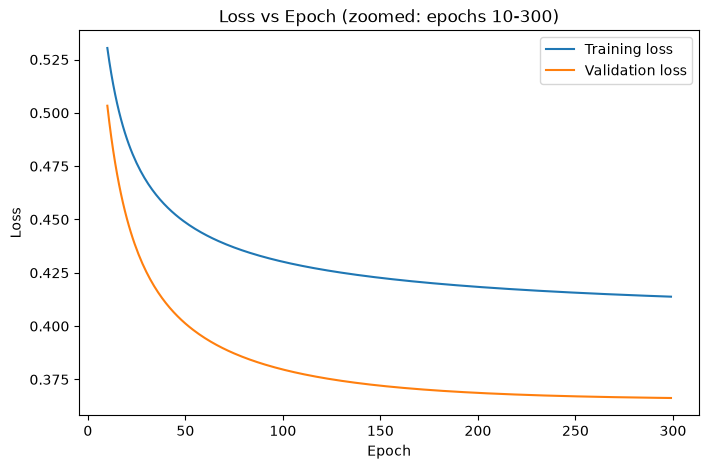

In [30]:
loss_df.iloc[10:300].plot(figsize=(8, 5), title='Loss vs Epoch (zoomed: epochs 10-300)', xlabel='Epoch', ylabel='Loss')

<Axes: title={'center': 'Loss vs Epoch (log scale)'}, xlabel='Epoch', ylabel='Loss (log scale)'>

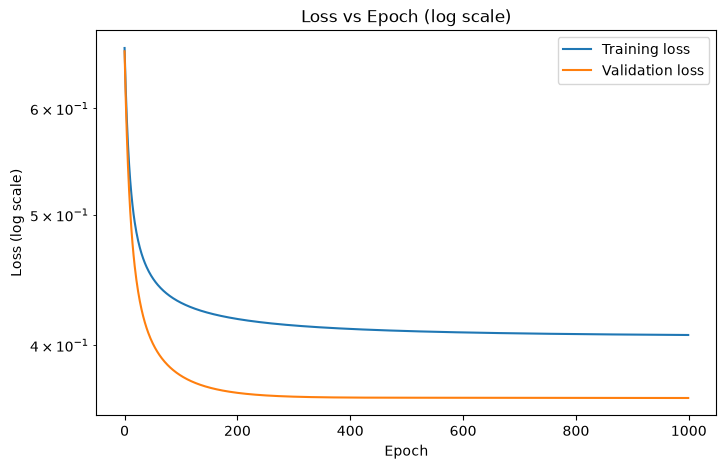

In [31]:
loss_df.plot(figsize=(8, 5), logy=True, title='Loss vs Epoch (log scale)', xlabel='Epoch', ylabel='Loss (log scale)')

### Training loss of the final model (full training set)

<Axes: title={'center': 'Final model: training loss vs epoch'}, xlabel='Epoch', ylabel='Binary cross-entropy loss'>

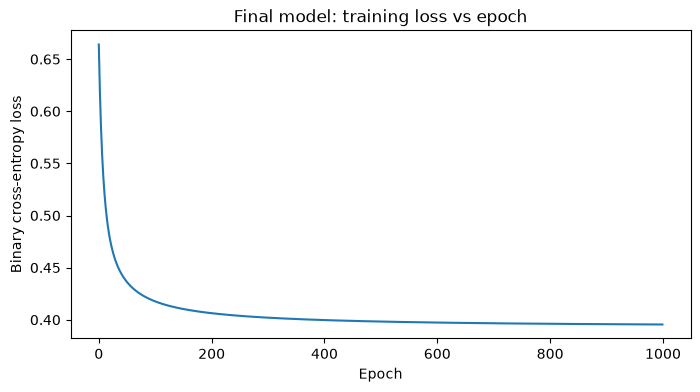

In [32]:
pd.Series(model.train_loss, name='Training loss').plot(figsize=(8, 4), title='Final model: training loss vs epoch',
                                                       xlabel='Epoch', ylabel='Binary cross-entropy loss')

## 7. Evaluation metrics
**This is the first and only point where the test set is used.** The test passengers are transformed with the statistics learned from the training data.

| Metric | Meaning |
|---|---|
| **Accuracy** | fraction of all passengers classified correctly |
| **Precision** | of the passengers predicted *survived*, how many really survived |
| **Recall** | of the passengers who really survived, how many the model found |
| **Specificity** | of the passengers who really died, how many the model correctly predicted as died |
| **F1-score** | harmonic mean of precision and recall (balances the two) |
| **ROC-AUC** | probability that a random survivor gets a higher score than a random non-survivor (0.5 = guessing, 1 = perfect) |
| **Log loss** | the cross-entropy loss itself; penalises confident wrong predictions |

In [ ]:
def confusion_matrix(y_true, y_pred):
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return tn, fp, fn, tp

def roc_curve(y_true, y_score):
    thresholds = np.unique(np.concatenate(([0.0, 1.0], y_score)))[::-1]
    P, N = np.sum(y_true == 1), np.sum(y_true == 0)
    tpr = np.array([np.sum((y_score >= t) & (y_true == 1)) / P for t in thresholds])
    fpr = np.array([np.sum((y_score >= t) & (y_true == 0)) / N for t in thresholds])
    return fpr, tpr

def auc_score(fpr, tpr):
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)    

def metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred)
    precision   = tp / (tp + fp) if (tp + fp) else 0.0
    recall      = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    p = np.clip(y_prob, 1e-15, 1 - 1e-15)
    return {
        'Accuracy'   : (tp + tn) / len(y_true),
        'Precision'  : precision,
        'Recall'     : recall,
        'Specificity': specificity,
        'F1-score'   : f1,
        'ROC-AUC'    : auc_score(*roc_curve(y_true, y_prob)),
        'Log loss'   : -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)),
    }

In [ ]:
X_test, y_test = transform(test_df, prep_final)  

prob_train, pred_train = model.predict_proba(X_train), model.predict(X_train)
prob_val,   pred_val   = dev_model.predict_proba(X_val), dev_model.predict(X_val)
prob_test,  pred_test  = model.predict_proba(X_test),  model.predict(X_test)

results = pd.DataFrame({
    'Train (final model)':      metrics(y_train, pred_train, prob_train),
    'Validation (dev. model)':  metrics(y_val,   pred_val,   prob_val),
    'Test (final model)':       metrics(y_test,  pred_test,  prob_test),
})
results.round(3)

,Train (final model),Validation (dev. model),Test (final model)
Accuracy,0.830,0.839,0.826
Precision,0.791,0.767,0.803
Recall,0.759,0.836,0.721
Specificity,0.875,0.841,0.891
F1-score,0.775,0.800,0.760
ROC-AUC,0.888,0.921,0.822
Log loss,0.395,0.365,0.477


### 7.1 Confusion matrix (test set)

In [35]:
tn, fp, fn, tp = confusion_matrix(y_test, pred_test)
cm = pd.DataFrame([[tn, fp], [fn, tp]], index=['Actual: Died', 'Actual: Survived'],
                  columns=['Predicted: Died', 'Predicted: Survived'])
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
cm.style.background_gradient(cmap='Blues')

TN=98  FP=12  FN=19  TP=49


,Predicted: Died,Predicted: Survived
Actual: Died,98,12
Actual: Survived,19,49


## 8. Result visualisations

### ROC curve (test set)

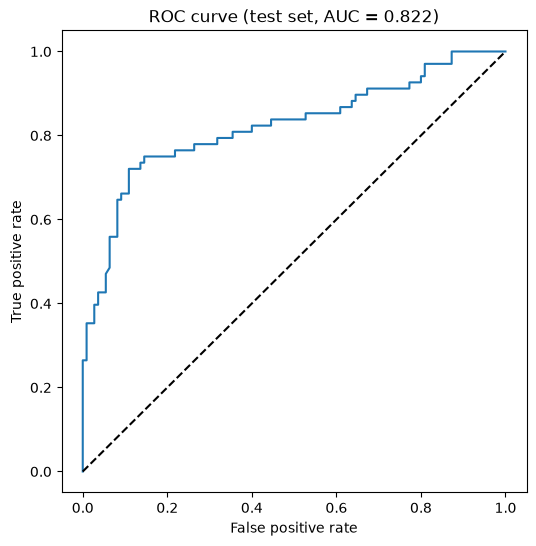

In [ ]:
fpr,tpr = roc_curve(y_test, prob_test)
ax = pd.DataFrame({'False positive rate': fpr, 'True positive rate': tpr}).plot(
    x='False positive rate', y='True positive rate', figsize=(6, 6), legend=False,
    title=f"ROC curve (test set, AUC = {results.loc['ROC-AUC', 'Test (final model)']:.3f})",
    xlabel='False positive rate', ylabel='True positive rate')
ax.plot([0, 1], [0, 1], 'k--') 

### Predicted probabilities by true class (test set)

<Axes: title={'center': 'Predicted survival probability (test set)'}, ylabel='Frequency'>

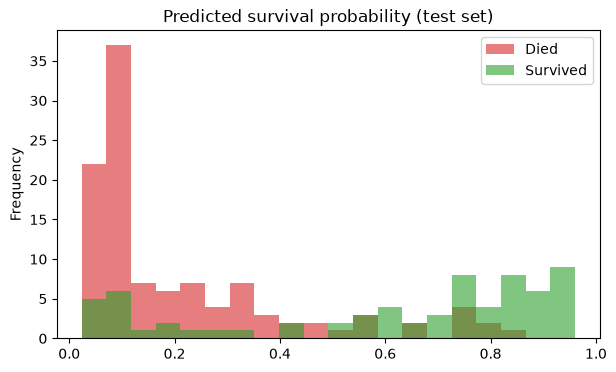

In [37]:
pd.DataFrame({'Died': pd.Series(prob_test[y_test == 0]),
              'Survived': pd.Series(prob_test[y_test == 1])}).plot.hist(
    bins=20, alpha=0.6, figsize=(7, 4), color=['tab:red', 'tab:green'],
    title='Predicted survival probability (test set)')

### Metrics at different decision thresholds (validation set)

<Axes: title={'center': 'Metrics vs decision threshold (validation set)'}, xlabel='Threshold', ylabel='Score'>

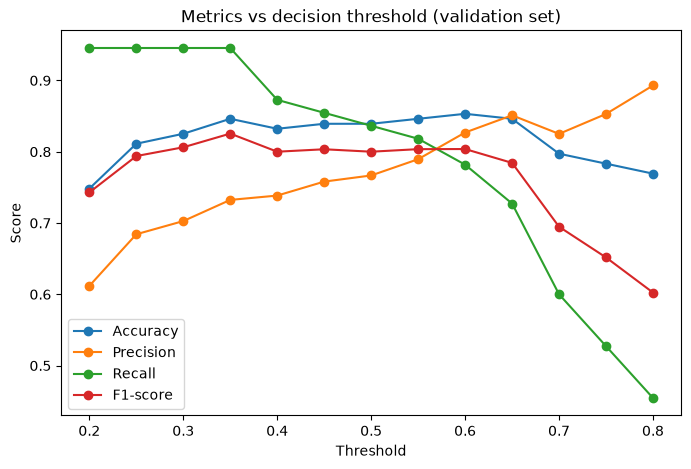

In [38]:
rows = []
for t in np.arange(0.2, 0.81, 0.05):
    m_ = metrics(y_val, (prob_val >= t).astype(int), prob_val)
    rows.append({'Threshold': round(t, 2), 'Accuracy': m_['Accuracy'], 'Precision': m_['Precision'],
                 'Recall': m_['Recall'], 'F1-score': m_['F1-score']})
pd.DataFrame(rows).set_index('Threshold').plot(figsize=(8, 5), marker='o', title='Metrics vs decision threshold (validation set)', ylabel='Score')

## Predict survival for one passenger (demo)

In [40]:
i = 0
p = model.predict_proba(X_test[i].reshape(1, -1))[0]
print(test_df.iloc[i][['Sex', 'Age', 'Pclass', 'Title']].to_dict())
print(f'Probability of survival: {p:.1%}')
print('Prediction :', 'Survived' if p >= 0.5 else 'Died')
print('Actual     :', 'Survived' if y_test[i] == 1 else 'Died')

{'Sex': 'male', 'Age': 17.0, 'Pclass': 3, 'Title': 'Mr'}
Probability of survival: 9.3%
Prediction : Died
Actual     : Died
